### Pregunta 1


Para aproximar la primera derivada se utilizan diferencias finitas de primer, segundo y tercer orden. Estas expresiones se obtienen mediante expansiones de Taylor alrededor del punto de evaluación, considerando un paso constante $h=\Delta x$.

**Primer orden**

Expandiendo la función en $x+h$:

$$
f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+O(h^3)
$$

Despejando la primera derivada y despreciando los términos de orden superior:

$$
f'(x)\approx\frac{f(x+h)-f(x)}{h}
$$

Esta aproximación tiene un error de truncamiento $O(h)$.

**Segundo orden**

Se consideran las expansiones de Taylor en ambos sentidos:

$$
f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+\frac{h^3}{6}f'''(x)+\frac{h^4}{24}f^{(4)}(x)+O(h^5)
$$

$$
f(x-h)=f(x)-hf'(x)+\frac{h^2}{2}f''(x)-\frac{h^3}{6}f'''(x)+\frac{h^4}{24}f^{(4)}(x)+O(h^5)
$$

Al restar ambas expresiones, los términos pares se cancelan:

$$
f(x+h)-f(x-h)=2hf'(x)+\frac{h^3}{3}f'''(x)+O(h^5)
$$

Dividiendo por $2h$ y despreciando los términos de error:

$$
f'(x)\approx\frac{f(x+h)-f(x-h)}{2h}
$$

El error de truncamiento es $O(h^2)$.

**Tercer orden**

Para obtener una aproximación de tercer orden se consideran cuatro puntos. Utilizando la expansión de Taylor con incrementos $kh$, para $k=1,2,3$:

$$
f(x+kh)=f(x)+khf'(x)+\frac{k^2h^2}{2}f''(x)+\frac{k^3h^3}{6}f'''(x)+O(h^4)
$$

Se combinan estas expansiones para cancelar los términos correspondientes a $f(x)$, $f''(x)$ y $f'''(x)$, conservando el término de la primera derivada.

La combinación resultante es:

$$
-11f(x)+18f(x+h)-9f(x+2h)+2f(x+3h)=6hf'(x)+O(h^4)
$$

Dividiendo por $6h$:

$$
f'(x)\approx\frac{-11f(x)+18f(x+h)-9f(x+2h)+2f(x+3h)}{6h}
$$

Esta aproximación tiene un error de truncamiento $O(h^3)$.

Finalmente, se evalúan las tres aproximaciones en $x=0.5$ con $h=0.25$, y se comparan con la derivada analítica mediante el error relativo.


In [6]:
def f(x):
    return -0.1*x**4 - 0.15*x**3 - 0.5*x**2 - 0.25*x + 1.2

def df(x):
    return -0.4*x**3 - 0.45*x**2 - x - 0.25

def df_primer_orden(x, h):
    return (f(x + h) - f(x)) / h

def df_segundo_orden(x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def df_tercer_orden(x, h):
    return (-11*f(x) + 18*f(x + h) - 9*f(x + 2*h) + 2*f(x + 3*h)) / (6*h)

x = 0.5
h = 0.25

print("Valor de la función en x =", x, "es:", f(x))
print("Valor de la derivada exacta en x =", x, "es:", df(x))
print("Valor de la derivada aproximada de primer orden en x =", x, "es:", df_primer_orden(x, h))
print("Valor de la derivada aproximada de segundo orden en x =", x, "es:", df_segundo_orden(x, h))
print("Valor de la derivada aproximada de tercer orden en x =", x, "es:", df_tercer_orden(x, h))
print("Error de la derivada aproximada de primer orden en x =", x, "es:", abs(df(x) - df_primer_orden(x, h))/abs(df(x))*100, "%")
print("Error de la derivada aproximada de segundo orden en x =", x, "es:", abs(df(x) - df_segundo_orden(x, h))/abs(df(x))*100, "%")
print("Error de la derivada aproximada de tercer orden en x =", x, "es:", abs(df(x) - df_tercer_orden(x, h))/abs(df(x))*100, "%")


Valor de la función en x = 0.5 es: 0.9249999999999999
Valor de la derivada exacta en x = 0.5 es: -0.9125
Valor de la derivada aproximada de primer orden en x = 0.5 es: -1.1546875
Valor de la derivada aproximada de segundo orden en x = 0.5 es: -0.9343750000000002
Valor de la derivada aproximada de tercer orden en x = 0.5 es: -0.9218749999999996
Error de la derivada aproximada de primer orden en x = 0.5 es: 26.541095890410972 %
Error de la derivada aproximada de segundo orden en x = 0.5 es: 2.3972602739726248 %
Error de la derivada aproximada de tercer orden en x = 0.5 es: 1.0273972602739263 %



### Análisis de resultados

La aproximación de primer orden presenta el mayor error relativo (26.54%). Al utilizar el esquema centrado de segundo orden, el error disminuye a 2.40%, mientras que con el esquema de tercer orden se reduce a 1.03%.

Para el paso utilizado, se observa que las aproximaciones de mayor orden entregan resultados más cercanos al valor analítico de $f'(0.5)=-0.9125$. Esto se debe a que las fórmulas de mayor orden eliminan más términos del error de truncamiento.


### Pregunta 2



Se resuelve la ecuación de advección pura unidimensional:

$$
\frac{\partial \phi}{\partial t}+c\frac{\partial \phi}{\partial x}=0
$$

Se utiliza un esquema implícito de Euler para el tiempo y diferencias retrógradas para el espacio, considerando $c>0$. La discretización resulta en:

$$
(1+C)\phi_i^{n+1}-C\phi_{i-1}^{n+1}=\phi_i^n
$$

donde $C=c\Delta t/\Delta x$ es el número de Courant. Agrupando las ecuaciones de los nodos interiores se obtiene un sistema matricial $A\phi^{n+1}=\phi^n+b$, que se resuelve en cada paso temporal.

Como el enunciado no especifica condiciones iniciales, se considera un pulso rectangular de altura 1 entre $x=0.2$ y $x=0.4$ m, con una condición de entrada $\phi(0,t)=0$. Se utiliza un dominio de 2 m y un tiempo final de 0.4 s.

A partir de este caso se estudia el efecto de variar $\Delta x$, $\Delta t$ y $c$ sobre la solución numérica.


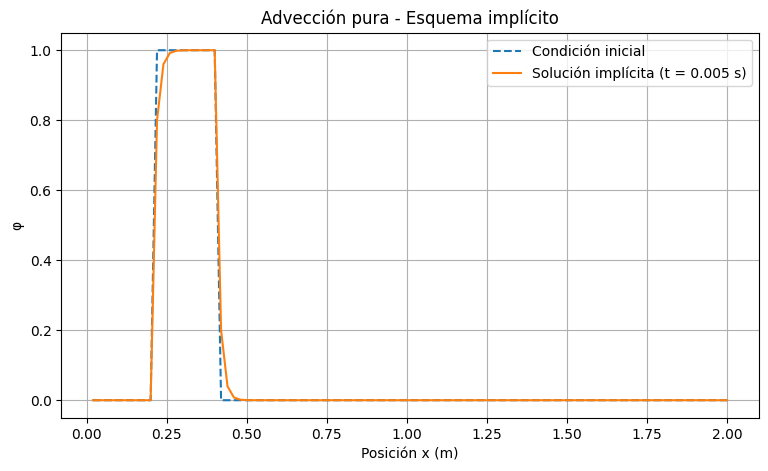

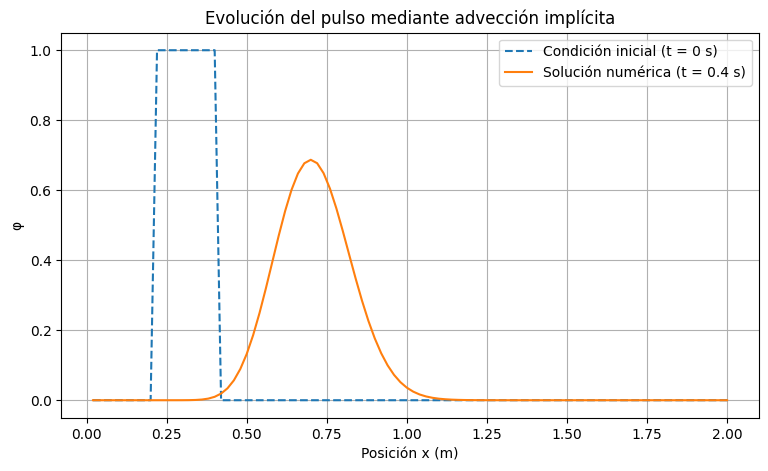

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def solucion_implicita(N, dx, dt, c, phi_actual, b):
    C = c * dt/dx
    A = np.zeros((N,N))
    for i in range(N):
        if i == 0:
            A[i][i] = 1 + C
        else:
            A[i][i] = 1 + C
            A[i][i-1] = -C
    return np.linalg.solve(A, phi_actual + b)


def simular_adveccion(N, dt, c, L, tf):
    dx = L / N
    x = np.linspace(dx, L, N)

    phi_inicial = np.zeros(N)
    phi_inicial[(x >= 0.2) & (x <= 0.4)] = 1.0

    phi_actual = phi_inicial.copy()
    b = np.zeros(N)

    Nt = int(round(tf / dt))

    for n in range(Nt):
        phi_actual = solucion_implicita(N, dx, dt, c, phi_actual, b)

    return x, phi_inicial, phi_actual


N = 100
L = 2.0
dx = L / N

dt = 0.005
c = 1.0
tf = 0.4

x = np.linspace(dx, L, N)

phi_inicial = np.zeros(N)
phi_inicial[(x >= 0.2) & (x <= 0.4)] = 1.0

phi_siguiente = solucion_implicita(N, dx, dt, c, phi_inicial, np.zeros(N))

x, phi_inicial, phi_final = simular_adveccion(N, dt, c, L, tf)


plt.figure(figsize=(9, 5))

plt.plot(x, phi_inicial, label="Condición inicial", linestyle="--")
plt.plot(x, phi_siguiente, label="Solución implícita (t = 0.005 s)")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Advección pura - Esquema implícito")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(9, 5))

plt.plot(x, phi_inicial, "--", label="Condición inicial (t = 0 s)")
plt.plot(x, phi_final, label="Solución numérica (t = 0.4 s)")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Evolución del pulso mediante advección implícita")
plt.legend()
plt.grid(True)

plt.show()


### Cambio de $\Delta x$

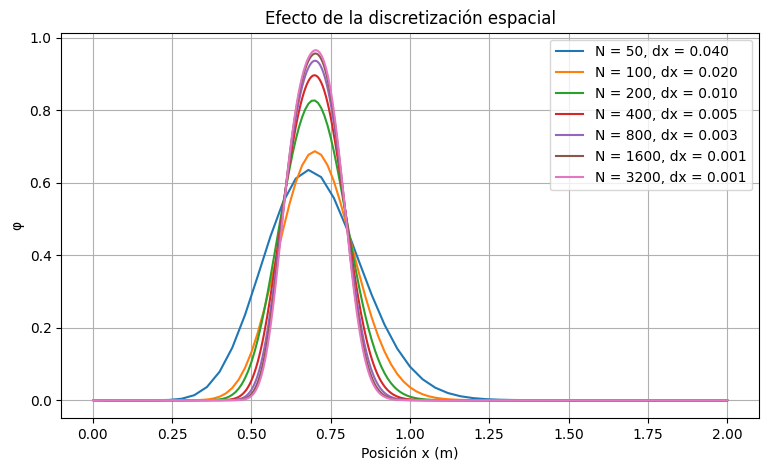

In [15]:

plt.figure(figsize=(9, 5))

for N in [50, 100, 200, 400, 800, 1600, 3200]:
    x, phi_inicial, phi_final = simular_adveccion(N, 0.005, 1.0, 2.0, 0.4)

    plt.plot(x, phi_final, label=f"N = {N}, dx = {2/N:.3f}")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Efecto de la discretización espacial")
plt.legend()
plt.grid(True)
plt.show()


### Cambio de $\Delta t$

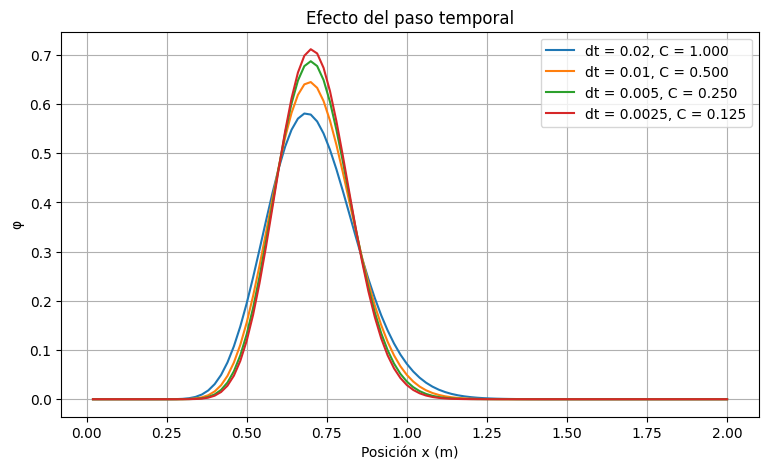

In [16]:

plt.figure(figsize=(9, 5))

N = 100
L = 2.0
c = 1.0
tf = 0.4

for dt in [0.02, 0.01, 0.005, 0.0025]:
    x, phi_inicial, phi_final = simular_adveccion(N, dt, c, L, tf)

    C = c * dt / (L / N)

    plt.plot(x, phi_final, label=f"dt = {dt}, C = {C:.3f}")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Efecto del paso temporal")
plt.legend()
plt.grid(True)
plt.show()


### Cambio de c

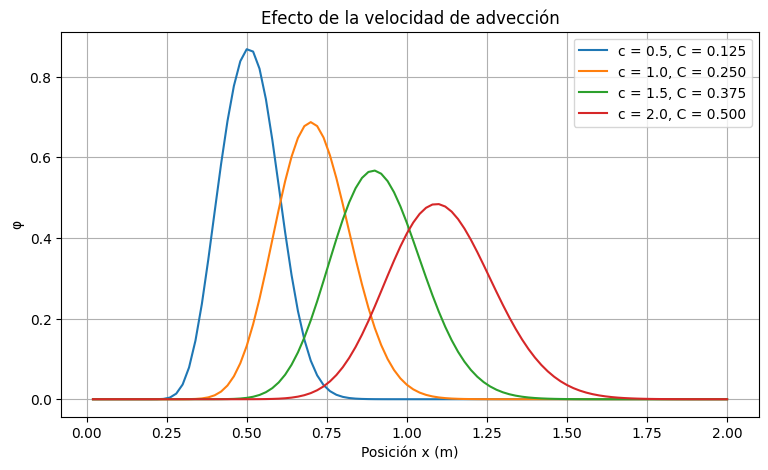

In [17]:

plt.figure(figsize=(9, 5))

N = 100
L = 2.0
dt = 0.005
tf = 0.4

for c in [0.5, 1.0, 1.5, 2.0]:
    x, phi_inicial, phi_final = simular_adveccion(N, dt, c, L, tf)

    C = c * dt / (L / N)

    plt.plot(x, phi_final, label=f"c = {c}, C = {C:.3f}")

plt.xlabel("Posición x (m)")
plt.ylabel("φ")
plt.title("Efecto de la velocidad de advección")
plt.legend()
plt.grid(True)
plt.show()



### Análisis de resultados

**Variación de $\Delta x$**

Al aumentar el número de nodos y disminuir $\Delta x$, se observa una reducción de la difusión numérica y una menor diferencia entre las soluciones de las mallas más finas. Sin embargo, el pulso no recupera completamente su forma rectangular, ya que el paso temporal se mantiene constante y sigue introduciendo error.

**Variación de $\Delta t$**

Al disminuir el paso temporal, las soluciones presentan una menor difusión numérica y conservan mejor la forma del pulso. Las diferencias se reducen progresivamente, aunque permanece el error asociado a la discretización espacial.

**Variación de $c$**

Al aumentar la velocidad de advección, el pulso se desplaza una mayor distancia durante el mismo tiempo de simulación. Además, cambia su forma debido al aumento de la difusión numérica, ya que el número de Courant también depende de $c$.

En general, los resultados muestran que tanto la discretización espacial como la temporal afectan la precisión del esquema. Aunque el método implícito upwind es estable para los parámetros considerados, presenta difusión numérica que suaviza los cambios bruscos de la condición inicial.



### Análisis del error numérico

Para determinar el orden del error se utilizan expansiones de Taylor sobre el esquema implícito implementado:

$$
\frac{\phi_i^{n+1}-\phi_i^n}{\Delta t}
+c\frac{\phi_i^{n+1}-\phi_{i-1}^{n+1}}{\Delta x}=0
$$

**Discretización temporal**

Expandiendo $\phi_i^n$ alrededor del tiempo $t^{n+1}$:

$$
\phi_i^n=\phi_i^{n+1}
-\Delta t\frac{\partial\phi}{\partial t}
+\frac{\Delta t^2}{2}\frac{\partial^2\phi}{\partial t^2}
+O(\Delta t^3)
$$

Reemplazando en la diferencia temporal:

$$
\frac{\phi_i^{n+1}-\phi_i^n}{\Delta t}
=
\frac{\partial\phi}{\partial t}
-\frac{\Delta t}{2}\frac{\partial^2\phi}{\partial t^2}
+O(\Delta t^2)
$$

Por lo tanto, el error de truncamiento temporal es $O(\Delta t)$.

**Discretización espacial**

De manera similar, expandiendo $\phi_{i-1}^{n+1}$ alrededor de $x_i$:

$$
\phi_{i-1}^{n+1}=\phi_i^{n+1}
-\Delta x\frac{\partial\phi}{\partial x}
+\frac{\Delta x^2}{2}\frac{\partial^2\phi}{\partial x^2}
+O(\Delta x^3)
$$

Reemplazando en la diferencia espacial:

$$
\frac{\phi_i^{n+1}-\phi_{i-1}^{n+1}}{\Delta x}
=
\frac{\partial\phi}{\partial x}
-\frac{\Delta x}{2}\frac{\partial^2\phi}{\partial x^2}
+O(\Delta x^2)
$$

En consecuencia, el error de truncamiento espacial es $O(\Delta x)$.

**Error del esquema completo**

Sustituyendo ambas expansiones en la ecuación discretizada:

$$
\frac{\partial\phi}{\partial t}
+c\frac{\partial\phi}{\partial x}
-\frac{\Delta t}{2}\frac{\partial^2\phi}{\partial t^2}
-\frac{c\Delta x}{2}\frac{\partial^2\phi}{\partial x^2}
+O(\Delta t^2+\Delta x^2)=0
$$

Como la solución exacta satisface la ecuación de advección pura:

$$
\frac{\partial\phi}{\partial t}
+c\frac{\partial\phi}{\partial x}=0
$$

El error de truncamiento queda determinado por:

$$
\tau=
-\frac{\Delta t}{2}\frac{\partial^2\phi}{\partial t^2}
-\frac{c\Delta x}{2}\frac{\partial^2\phi}{\partial x^2}
+O(\Delta t^2+\Delta x^2)
$$

Por lo tanto:

$$
\boxed{\tau=O(\Delta x+\Delta t)}
$$

El esquema es consistente de primer orden tanto en espacio como en tiempo. Además, para $c>0$, el esquema implícito upwind es estable, por lo que el error de la solución también converge con orden $O(\Delta x+\Delta t)$ para soluciones suficientemente suaves, con condiciones iniciales y de borde compatibles.


### Pregunta 3

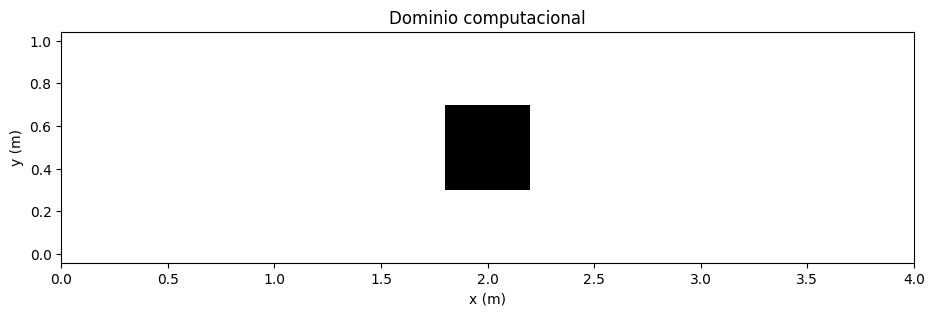

In [18]:

import numpy as np
import matplotlib.pyplot as plt

L = 4.0
d = 1.0
l = 0.4

Nx = 80
Ny = 20

dx = L / Nx
dy = d / Ny

x = np.linspace(dx/2, L-dx/2, Nx)
y = np.linspace(dy/2, d-dy/2, Ny)

X, Y = np.meshgrid(x, y)

bloque = (abs(X - L/2) < l/2) & (abs(Y - d/2) < l/2)

plt.figure(figsize=(11, 3))
plt.pcolormesh(X, Y, bloque, shading="nearest", cmap="Greys")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Dominio computacional")
plt.axis("equal")
plt.show()


In [20]:
fluido = ~bloque

indices = -np.ones((Ny, Nx), dtype=int)

contador = 0

for j in range(Ny):
    for i in range(Nx):
        if fluido[j, i]:
            indices[j, i] = contador
            contador += 1



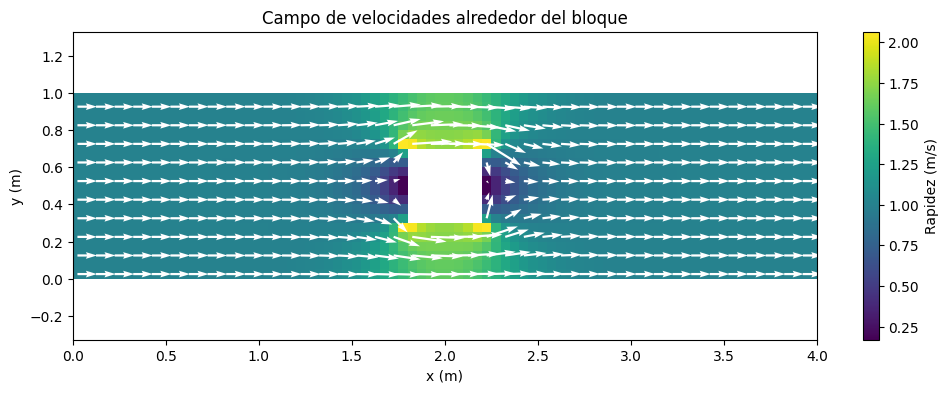

In [23]:
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

v0 = 1.0

n_fluido = np.sum(fluido)

A = lil_matrix((n_fluido, n_fluido))
b = np.zeros(n_fluido)

for j in range(Ny):
    for i in range(Nx):

        if bloque[j, i]:
            continue

        P = indices[j, i]

        vecinos = [
            (i+1, j, dy/dx),
            (i-1, j, dy/dx),
            (i, j+1, dx/dy),
            (i, j-1, dx/dy)
        ]

        for ni, nj, coef in vecinos:

            if 0 <= ni < Nx and 0 <= nj < Ny:

                if fluido[nj, ni]:
                    V = indices[nj, ni]

                    A[P, P] += coef
                    A[P, V] -= coef

            else:
                if ni < 0:
                    b[P] -= v0 * dy

                elif ni >= Nx:
                    b[P] += v0 * dy

# Fijar un valor de referencia para el potencial
referencia = indices[0, 0]
A[referencia, :] = 0
A[referencia, referencia] = 1
b[referencia] = 0

phi_vector = spsolve(A.tocsr(), b)

phi = np.full((Ny, Nx), np.nan)
phi[fluido] = phi_vector



u = np.full((Ny, Nx), np.nan)
v = np.full((Ny, Nx), np.nan)

for j in range(Ny):
    for i in range(Nx):

        if bloque[j, i]:
            continue

        # Velocidades en las caras este y oeste
        if i == Nx - 1:
            ue = v0
        elif bloque[j, i+1]:
            ue = 0
        else:
            ue = (phi[j, i+1] - phi[j, i]) / dx

        if i == 0:
            uw = v0
        elif bloque[j, i-1]:
            uw = 0
        else:
            uw = (phi[j, i] - phi[j, i-1]) / dx

        # Velocidades en las caras norte y sur
        if j == Ny - 1 or bloque[j+1, i]:
            vn = 0
        else:
            vn = (phi[j+1, i] - phi[j, i]) / dy

        if j == 0 or bloque[j-1, i]:
            vs = 0
        else:
            vs = (phi[j, i] - phi[j-1, i]) / dy

        u[j, i] = (ue + uw) / 2
        v[j, i] = (vn + vs) / 2

velocidad = np.sqrt(u**2 + v**2)


plt.figure(figsize=(12, 4))

plt.pcolormesh(X, Y, velocidad, shading="nearest", cmap="viridis")
plt.colorbar(label="Rapidez (m/s)")

salto = 2

plt.quiver(
    X[::salto, ::salto],
    Y[::salto, ::salto],
    u[::salto, ::salto],
    v[::salto, ::salto],
    color="white"
)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Campo de velocidades alrededor del bloque")

plt.axis("equal")
plt.show()





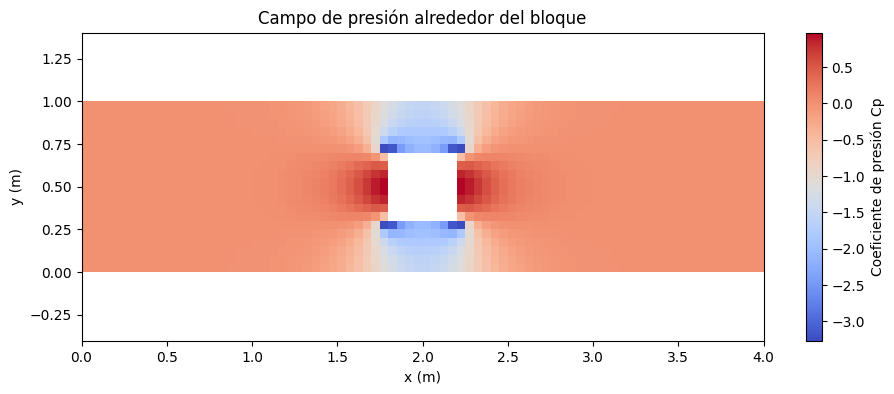

Cp mínimo: -3.266929515905505
Cp máximo: 0.9714831833215832


In [24]:

Cp = 1 - velocidad**2 / v0**2

plt.figure(figsize=(11, 4))

plt.pcolormesh(X, Y, Cp, shading="nearest", cmap="coolwarm")
plt.colorbar(label="Coeficiente de presión Cp")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Campo de presión alrededor del bloque")

plt.axis("equal")
plt.show()

print("Cp mínimo:", np.nanmin(Cp))
print("Cp máximo:", np.nanmax(Cp))
